# 1. Setup and Data Loading


### Cell 1 overview
Import the libraries used for data handling, visualization, preprocessing, model training, and evaluation. Keeping imports together makes the notebook dependencies easy to review.


In [77]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns 
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
import joblib
import os
from typing import Dict, Any, Tuple

### Cell 2 overview
Load the shopping-session data into a pandas DataFrame. Confirm that the CSV path points to the intended dataset before running this cell.


In [78]:
df=pd.read_csv("M:\PRG\online_shoppers_intention.csv")

<>:1: SyntaxWarning: invalid escape sequence '\P'
<>:1: SyntaxWarning: invalid escape sequence '\P'
C:\Users\Center\AppData\Local\Temp\ipykernel_21860\3199143385.py:1: SyntaxWarning: invalid escape sequence '\P'
  df=pd.read_csv("M:\PRG\online_shoppers_intention.csv")


# 2. Exploratory Data Analysis (EDA)


### Cell 3 overview
Preview the first records to check column names, value formats, and whether the file was parsed as expected.


In [79]:
df.head()

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


### Cell 4 overview
Return the number of rows and columns. This gives a quick sense of dataset size before analysis.


In [80]:
df.shape

(12330, 18)

### Cell 5 overview
Separate the predictor columns from the target, Revenue. This defines the classification task: predict whether a session ends in a purchase.


In [81]:
X= df.drop(columns=['Revenue'])
y= df['Revenue']

### Cell 6 overview
Split the data into training and test sets while preserving the target-class proportions. The test set is held out for later evaluation.


In [82]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42,stratify=y)

print(f"Train set shape: {X_train.shape}")
print(f"Test set shape: {X_test.shape}")

Train set shape: (9864, 17)
Test set shape: (2466, 17)


### Cell 7 overview
Inspect column data types and non-null counts. Use this output to identify columns that may need type conversion or missing-value handling.


In [83]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 12330 entries, 0 to 12329
Data columns (total 18 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Administrative           12330 non-null  int64  
 1   Administrative_Duration  12330 non-null  float64
 2   Informational            12330 non-null  int64  
 3   Informational_Duration   12330 non-null  float64
 4   ProductRelated           12330 non-null  int64  
 5   ProductRelated_Duration  12330 non-null  float64
 6   BounceRates              12330 non-null  float64
 7   ExitRates                12330 non-null  float64
 8   PageValues               12330 non-null  float64
 9   SpecialDay               12330 non-null  float64
 10  Month                    12330 non-null  str    
 11  OperatingSystems         12330 non-null  int64  
 12  Browser                  12330 non-null  int64  
 13  Region                   12330 non-null  int64  
 14  TrafficType              12330 no

### Cell 8 overview
Count missing values in each column. This helps determine whether imputation is needed and which columns require attention.


In [84]:
df.isnull().sum()

Administrative             0
Administrative_Duration    0
Informational              0
Informational_Duration     0
ProductRelated             0
ProductRelated_Duration    0
BounceRates                0
ExitRates                  0
PageValues                 0
SpecialDay                 0
Month                      0
OperatingSystems           0
Browser                    0
Region                     0
TrafficType                0
VisitorType                0
Weekend                    0
Revenue                    0
dtype: int64

### Cell 9 overview
Summarize numeric columns with count, mean, spread, and quartiles. Large gaps between quartiles or extremes can indicate skew or outliers.


In [85]:
df.describe()

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,OperatingSystems,Browser,Region,TrafficType
count,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000
mean,2.315166,80.818611,0.503569,34.472398,31.731468,1194.746220,0.022191,0.043073,5.889258,0.061427,2.124006,2.357097,3.147364,4.069586
std,3.321784,176.779107,1.270156,140.749294,44.475503,1913.669288,0.048488,0.048597,18.568437,0.198917,0.911325,1.717277,2.401591,4.025169
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000,1.000000,1.000000
25%,0.000000,0.000000,0.000000,0.000000,7.000000,184.137500,0.000000,0.014286,0.000000,0.000000,2.000000,2.000000,1.000000,2.000000
50%,1.000000,7.500000,0.000000,0.000000,18.000000,598.936905,0.003112,0.025156,0.000000,0.000000,2.000000,2.000000,3.000000,2.000000
75%,4.000000,93.256250,0.000000,0.000000,38.000000,1464.157214,0.016813,0.050000,0.000000,0.000000,3.000000,2.000000,4.000000,4.000000
max,27.000000,3398.750000,24.000000,2549.375000,705.000000,63973.522230,0.200000,0.200000,361.763742,1.000000,8.000000,13.000000,9.000000,20.000000


### Cell 10 overview
Count fully duplicated rows. Duplicates may affect summaries and model fitting, so review this count before deciding how to handle them.


In [86]:
df.duplicated().sum()

np.int64(125)

### Cell 11 overview
Inspect the frequency of Month and VisitorType categories. This reveals which groups are common and whether some categories are sparse.


In [87]:
print("Month Values:")
print(df['Month'].value_counts())

print("\nVisitorType Values:")
print(df['VisitorType'].value_counts())

Month Values:
Month
May     3364
Nov     2998
Mar     1907
Dec     1727
Oct      549
Sep      448
Aug      433
Jul      432
June     288
Feb      184
Name: count, dtype: int64

VisitorType Values:
VisitorType
Returning_Visitor    10551
New_Visitor           1694
Other                   85
Name: count, dtype: int64


### Cell 12 overview
Inspect both the number and proportion of purchases and non-purchases. The class imbalance matters when choosing metrics and interpreting accuracy.


In [88]:
print(df['Revenue'].value_counts())

print("\nPercentage:")
print(df['Revenue'].value_counts(normalize=True) * 100)

Revenue
False    10422
True      1908
Name: count, dtype: int64

Percentage:
Revenue
False    84.525547
True     15.474453
Name: proportion, dtype: float64


### Cell 13 overview
Calculate the observed purchase rate for each month and rank the months. Rates describe conversion within each month, while group sizes determine how stable those rates may be.


In [89]:
month_purchase = df.groupby('Month')['Revenue'].mean() * 100

print(month_purchase.sort_values(ascending=False))

Month
Nov     25.350233
Oct     20.947177
Sep     19.196429
Aug     17.551963
Jul     15.277778
Dec     12.507238
May     10.850178
June    10.069444
Mar     10.068170
Feb      1.630435
Name: Revenue, dtype: float64


### Cell 14 overview
Calculate and rank purchase rates by visitor type. Consider the size of each visitor group before interpreting small differences.


In [90]:
visitor_purchase = df.groupby('VisitorType')['Revenue'].mean() * 100

print(visitor_purchase.sort_values(ascending=False))

VisitorType
New_Visitor          24.911452
Other                18.823529
Returning_Visitor    13.932329
Name: Revenue, dtype: float64


### Cell 15 overview
Compare mean counts of administrative, informational, and product-related pages for purchasing and non-purchasing sessions. These are descriptive group differences, not evidence of causation.


In [91]:
print(df.groupby('Revenue')[['Administrative', 'Informational', 'ProductRelated']].mean())

         Administrative  Informational  ProductRelated
Revenue                                               
False          2.117732       0.451833       28.714642
True           3.393606       0.786164       48.210168


### Cell 16 overview
Summarize PageValues by purchase outcome using mean, median, minimum, and maximum. Comparing the median as well as the mean helps reveal skew and extreme values.


In [92]:
print(df.groupby('Revenue')['PageValues'].agg(['mean', 'median', 'min', 'max']))

              mean     median  min         max
Revenue                                       
False     1.975998   0.000000  0.0  246.758590
True     27.264518  16.758134  0.0  361.763742


### Cell 17 overview
Display sample rows that belong to duplicated records. Inspect whether duplicates are exact repeats and decide whether they are meaningful sessions or data artifacts.


In [93]:
duplicated_rows = df[df.duplicated(keep=False)]
display(duplicated_rows.head())

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
85,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Feb,1,1,1,3,Returning_Visitor,False,False
132,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Feb,3,2,3,3,Returning_Visitor,False,False
158,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Feb,1,1,1,3,Returning_Visitor,False,False
159,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Feb,3,2,3,3,Returning_Visitor,False,False
178,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Feb,3,2,3,3,Returning_Visitor,False,False


### Cell 18 overview
Convert selected categorical columns to pandas category dtype. This clarifies their role as categories and supports consistent downstream feature selection.


In [94]:
categorical_cols = ['Browser', 'Region', 'TrafficType', 'VisitorType', 'Weekend']
for col in categorical_cols:
    if col in df.columns:
        df[col]=df[col].astype('category')

print(df[['Browser', 'Region', 'TrafficType', 'VisitorType' , 'Weekend']].dtypes)    


Browser        category
Region         category
TrafficType    category
VisitorType    category
Weekend        category
dtype: object


### Cell 19 overview
Inspect the observed month labels and map them to a numeric calendar order where applicable. Check the mapping against the actual labels before relying on it.


In [95]:
if 'Month' in df.columns:
    print("\nUnique values of the Month column:", df['Month'].unique())
    
    month_mapping = {'Jan': 1, 'Feb': 2, 'Mar': 3, 'Apr': 4, 'May': 5, 'June': 6, 
                     'Jul': 7, 'Aug': 8, 'Sep': 9, 'Oct': 10, 'Nov': 11, 'Dec': 12}
    


Unique values of the Month column: <ArrowStringArray>
['Feb', 'Mar', 'May', 'Oct', 'June', 'Jul', 'Aug', 'Nov', 'Sep', 'Dec']
Length: 10, dtype: str


### Cell 20 overview
List all column names for a final schema check and to make later feature references easier to verify.


In [96]:
df.columns

Index(['Administrative', 'Administrative_Duration', 'Informational',
       'Informational_Duration', 'ProductRelated', 'ProductRelated_Duration',
       'BounceRates', 'ExitRates', 'PageValues', 'SpecialDay', 'Month',
       'OperatingSystems', 'Browser', 'Region', 'TrafficType', 'VisitorType',
       'Weekend', 'Revenue'],
      dtype='str')

# 3. Feature Preparation and Preprocessing


### Cell 21 overview
Identify numeric and categorical predictors so each group can receive a suitable preprocessing method.


In [97]:
numeric_features = X.select_dtypes(include=['int64', 'float64']).columns.tolist()
categorical_features = X.select_dtypes(include=['category', 'object', 'bool']).columns.tolist()

C:\Users\Center\AppData\Local\Temp\ipykernel_21860\2362196193.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X.select_dtypes(include=['category', 'object', 'bool']).columns.tolist()


### Cell 22 overview
Define a numeric preprocessing pipeline that fills missing values with the median and standardizes the features. The median is less sensitive to extreme values than the mean.


In [98]:
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')), 
    ('scaler', StandardScaler())])

### Cell 23 overview
Define a categorical preprocessing pipeline that fills missing values with the most frequent category and one-hot encodes values. Ignoring unknown categories lets the transformer handle categories first seen at prediction time.


In [99]:
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))])

### Cell 24 overview
Combine the numeric and categorical transformations in a ColumnTransformer. This applies each operation only to its designated feature columns.


In [100]:
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features)])

### Cell 25 overview
Wrap the preprocessing steps in a pipeline so transformations can be reused consistently during model fitting and inference.


In [101]:
full_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor)])

print("پایپ‌لاین پیش‌پردازش با موفقیت ساخته شد!")

پایپ‌لاین پیش‌پردازش با موفقیت ساخته شد!


### Cell 26 overview
This Markdown cell documents why the preprocessing choices were made: median imputation and scaling for numeric fields, and mode imputation plus one-hot encoding for categories. Fit transformations on training data only to avoid information leakage.


In [102]:
pipeline_rf = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(class_weight='balanced', random_state=42))])

# 4. Random Forest Pipeline and Hyperparameter Tuning


### Cell 27 overview
Create a complete pipeline with preprocessing followed by a class-balanced Random Forest. Keeping both steps together allows cross-validation to fit preprocessing separately inside each fold.


In [103]:
param_grid = {
    'classifier__n_estimators': [50, 100, 200],
    'classifier__max_depth': [10, 20, None],
    'classifier__min_samples_split': [2, 5]}

### Cell 28 overview
Define candidate tree counts, maximum depths, and minimum split sizes for the Random Forest search. The grid controls the trade-off between model complexity and generalization.


In [104]:
grid_search = GridSearchCV(estimator=pipeline_rf,param_grid=param_grid,cv=5,scoring='f1',n_jobs=-1)

print("Training and tuning hyperparameters using CV on Train set...")
grid_search.fit(X_train, y_train)

print("\nBest Parameters found:", grid_search.best_params_)
print("Best CV F1-Score:", grid_search.best_score_)

Training and tuning hyperparameters using CV on Train set...

Best Parameters found: {'classifier__max_depth': 20, 'classifier__min_samples_split': 5, 'classifier__n_estimators': 200}
Best CV F1-Score: 0.6864290599853475


### Cell 29 overview
Run five-fold cross-validation on the training set and select settings by F1 score. F1 balances precision and recall, which is useful when purchase sessions are the minority class.


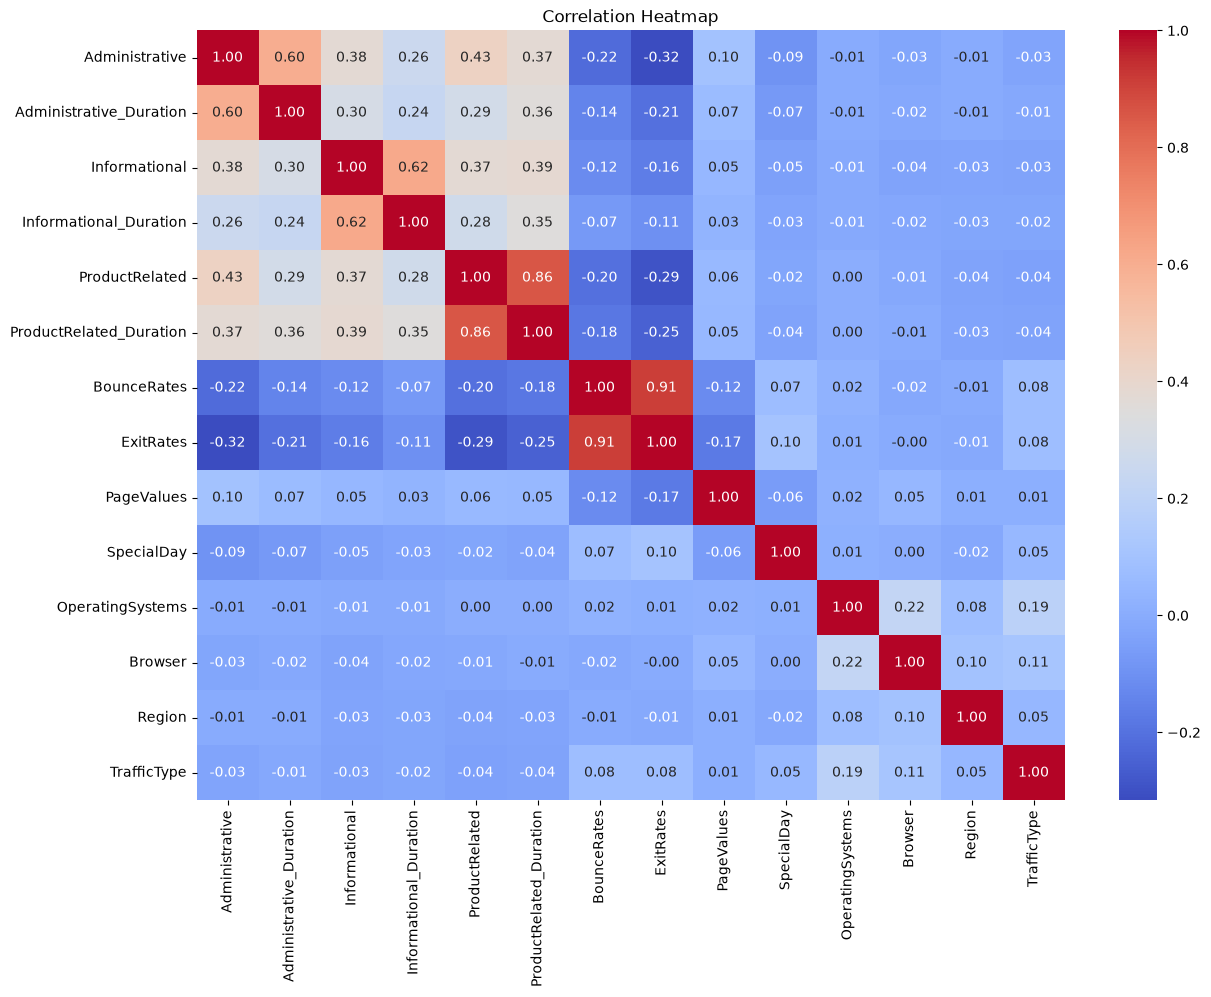

In [105]:
correlation = X.select_dtypes(include='number').corr()

plt.figure(figsize=(14, 10))

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f')

plt.title('Correlation Heatmap')
plt.show()

# 5. EDA Visualizations


### Cell 30 overview
Plot pairwise correlations among numeric predictors. Strong associations can signal overlapping information; correlation alone does not establish a causal relationship or predictive importance.


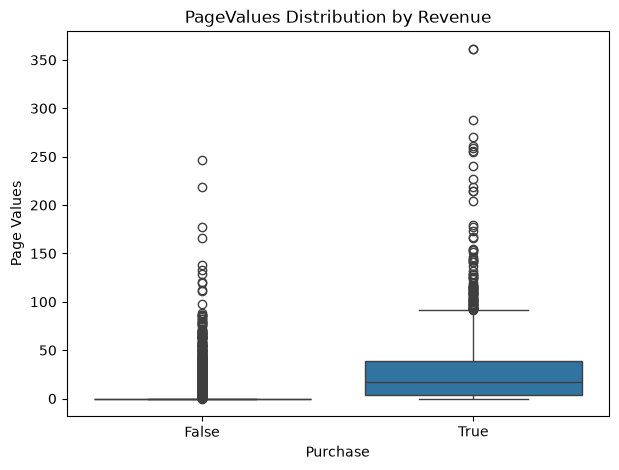

In [106]:
plt.figure(figsize=(7, 5))

sns.boxplot(
    data=df,
    x='Revenue',
    y='PageValues')

plt.title('PageValues Distribution by Revenue')
plt.xlabel('Purchase')
plt.ylabel('Page Values')

plt.show()

### Chart analysis
The heatmap shows which numeric predictors move together. Read the strongest off-diagonal cells as possible redundancy or shared behavior, then verify any modeling consequence with validation. Revenue is not included here because the correlation is calculated from X, so this figure does not measure each feature’s direct relationship with the target.

### Cell 31 overview
Compare PageValues distributions for purchase and non-purchase sessions. The box plot highlights differences in typical values and spread; points beyond whiskers represent potential outliers.


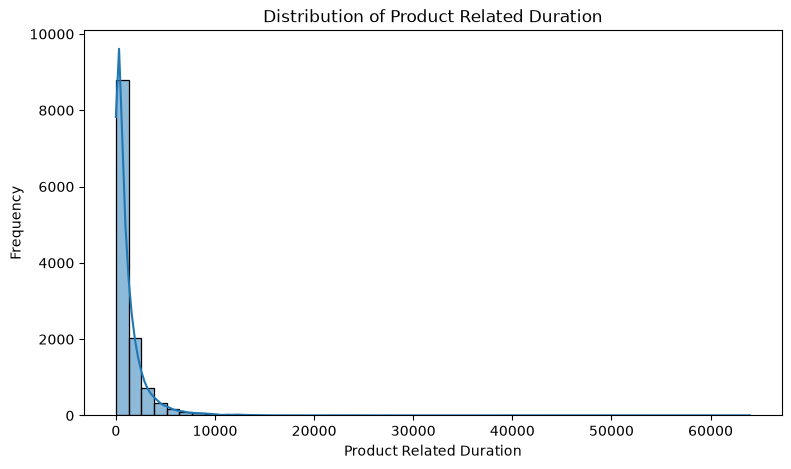

In [107]:
plt.figure(figsize=(9, 5))

sns.histplot(
    data=df,
    x='ProductRelated_Duration',
    bins=50,
    kde=True)

plt.title('Distribution of Product Related Duration')
plt.xlabel('Product Related Duration')
plt.ylabel('Frequency')

plt.show()

### Chart analysis
The purchase group has substantially higher PageValues in this dataset: its mean is about 27.26 and median about 16.77, while the non-purchase group has a mean near 1.98 and median 0. This makes PageValues a strong descriptive signal in these sessions. Its zero-heavy distribution and possible extreme values mean the median and box plot are more representative than the mean alone; the relationship is predictive association, not proof of cause.

### Cell 32 overview
Plot the distribution of ProductRelated_Duration with a histogram and density curve. Look for skew, concentration near zero, and a long upper tail that may affect scaling or model behavior.


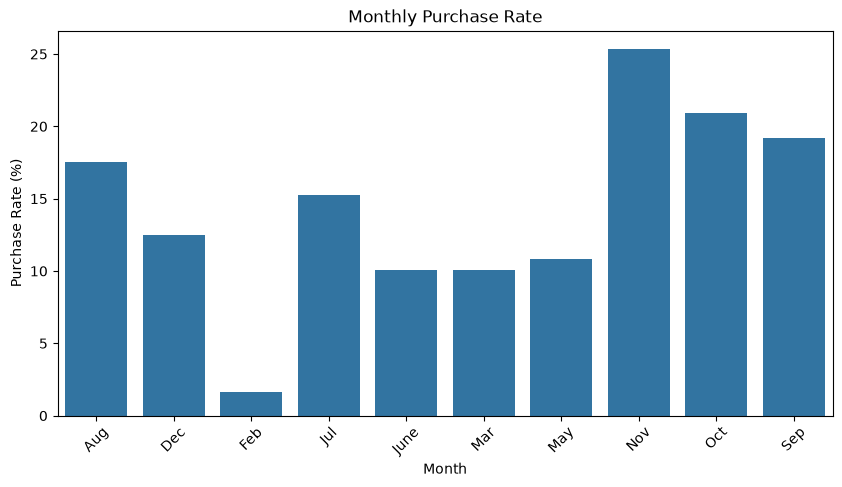

In [108]:
plt.figure(figsize=(10, 5))

sns.barplot(
    x=month_purchase.index,
    y=month_purchase.values)

plt.title('Monthly Purchase Rate')
plt.xlabel('Month')
plt.ylabel('Purchase Rate (%)')
plt.xticks(rotation=45)

plt.show()

### Chart analysis
The histogram is expected to show how session duration is distributed, including where most sessions cluster and whether a long right tail exists. A right-skew would mean a small number of very long sessions pull the mean upward. Compare this with the median and consider whether a log transform or robust scaling is useful; do not treat longer browsing time as proof that a purchase will occur.

### Cell 33 overview
Plot the mean purchase rate for each month. Read this together with the number of sessions per month, because a high rate from a small group is less stable.


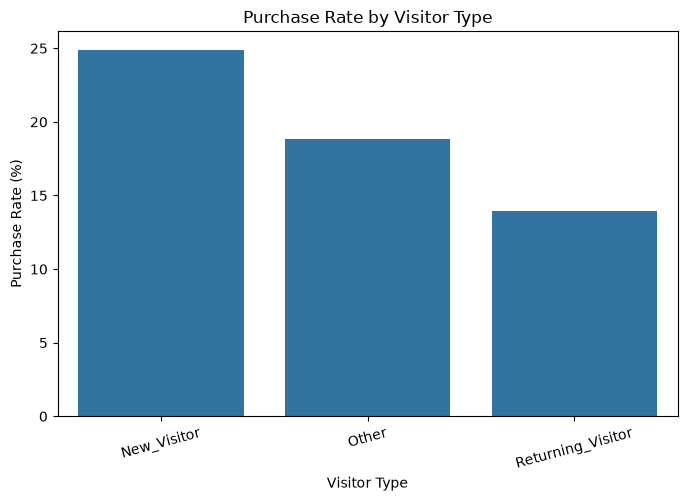

In [109]:
plt.figure(figsize=(8, 5))

sns.barplot(
    x=visitor_purchase.index,
    y=visitor_purchase.values)

plt.title('Purchase Rate by Visitor Type')
plt.xlabel('Visitor Type')
plt.ylabel('Purchase Rate (%)')
plt.xticks(rotation=15)

plt.show()

### Chart analysis
November has the highest observed purchase rate at about 25.35% (2,998 sessions), followed by October at about 20.95% (549 sessions); February is lowest at about 1.63% (184 sessions). May contains the most sessions (3,364) but converts at about 10.85%. Seasonality may be relevant, but the data alone cannot explain why the rates differ, and smaller monthly groups make estimates less stable.

### Cell 34 overview
Plot the mean purchase rate for each visitor type. The displayed percentages show association with conversion, not that visitor type itself causes a purchase.


In [110]:
numeric_features = X_train.select_dtypes(
    include=['int64', 'float64']).columns

categorical_features = X_train.select_dtypes(
    include=['object', 'bool']).columns

print("Numeric Features:")
print(list(numeric_features))

print("\nCategorical Features:")
print(list(categorical_features))

Numeric Features:
['Administrative', 'Administrative_Duration', 'Informational', 'Informational_Duration', 'ProductRelated', 'ProductRelated_Duration', 'BounceRates', 'ExitRates', 'PageValues', 'SpecialDay', 'OperatingSystems', 'Browser', 'Region', 'TrafficType']

Categorical Features:
['Month', 'VisitorType', 'Weekend']


C:\Users\Center\AppData\Local\Temp\ipykernel_21860\2555941067.py:4: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X_train.select_dtypes(


### Chart analysis
New visitors have an observed purchase rate of about 24.91% across 1,694 sessions, compared with about 13.93% for returning visitors across 10,551 sessions. The “Other” group is about 18.82% across only 85 sessions, so its rate is comparatively uncertain. These are group-level associations; the chart does not establish that visitor type causes purchase behavior.

# 6. Classification Models


### Cell 35 overview
List numeric and categorical predictors as they appear in the training split. This is a diagnostic check that the preprocessing feature groups match expectations.


In [111]:
baseline_model = DummyClassifier(strategy='most_frequent')
baseline_model.fit(X_train, y_train)

y_pred_baseline = baseline_model.predict(X_test)

print("--- Baseline Model Classification Report ---")
print(classification_report(y_test, y_pred_baseline, zero_division=0))

--- Baseline Model Classification Report ---
              precision    recall  f1-score   support

       False       0.85      1.00      0.92      2084
        True       0.00      0.00      0.00       382

    accuracy                           0.85      2466
   macro avg       0.42      0.50      0.46      2466
weighted avg       0.71      0.85      0.77      2466



### Cell 36 overview
Fit a majority-class baseline and report its classification metrics. This sets a simple reference point that more complex models should improve upon, especially for the purchase class.


In [112]:
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numeric_features),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features)])

### Cell 37 overview
Define transformations for the numeric and categorical training features. This cell uses a second preprocessor setup for the following model comparisons.


In [113]:
X_train_processed = preprocessor.fit_transform(X_train)

X_test_processed = preprocessor.transform(X_test)

print("X_train Processed Shape:", X_train_processed.shape)
print("X_test Processed Shape:", X_test_processed.shape)

X_train Processed Shape: (9864, 29)
X_test Processed Shape: (2466, 29)


### Cell 38 overview
Fit the preprocessor on the training set and transform both training and test features. Fitting only on training data prevents the test set from influencing preprocessing parameters.


In [114]:
print("Training Target Distribution:")
print(y_train.value_counts())

print("\nTraining Target Percentage:")
print(y_train.value_counts(normalize=True) * 100)

Training Target Distribution:
Revenue
False    8338
True     1526
Name: count, dtype: int64

Training Target Percentage:
Revenue
False    84.529603
True     15.470397
Name: proportion, dtype: float64


### Cell 39 overview
Inspect the target distribution in the training split as counts and percentages. Use it to understand how class imbalance may shape model results.


In [115]:
lr_model = LogisticRegression(max_iter=1000, random_state=42)

lr_model.fit(X_train_processed, y_train)

,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lb

### Cell 40 overview
Fit Logistic Regression on the preprocessed training features. This linear model provides an interpretable baseline for comparison with nonlinear methods.


In [116]:
y_pred_lr = lr_model.predict(X_test_processed)

### Cell 41 overview
Generate purchase predictions for the held-out test data using Logistic Regression.


In [117]:
lr_accuracy = accuracy_score(y_test, y_pred_lr)

print("Logistic Regression Accuracy:", lr_accuracy)

Logistic Regression Accuracy: 0.8811841038118411


### Cell 42 overview
Calculate test accuracy for Logistic Regression. Because classes are imbalanced, read accuracy alongside precision, recall, and F1 for the purchase class.


In [118]:
knn_model = KNeighborsClassifier(n_neighbors=5)

knn_model.fit(X_train_processed, y_train)

print("KNN trained successfully!")

KNN trained successfully!


### Cell 43 overview
Fit a K-Nearest Neighbors classifier using five neighbors on the transformed training data.


In [119]:
y_pred_knn = knn_model.predict(X_test_processed)

### Cell 44 overview
Generate test-set predictions with KNN.


In [120]:
knn_accuracy = accuracy_score(y_test, y_pred_knn)

print("KNN Accuracy:", knn_accuracy)

KNN Accuracy: 0.8730738037307381


### Cell 45 overview
Calculate test accuracy for KNN and compare it with the baseline and other evaluation metrics.


In [121]:
svm_model = SVC(
    kernel='rbf',
    probability=True,
    random_state=42)

svm_model.fit(X_train_processed, y_train)

print("SVM trained successfully!")

c:\Users\Center\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


SVM trained successfully!


### Cell 46 overview
Fit an RBF-kernel Support Vector Machine. Probability estimates are enabled for compatibility with soft voting later in the notebook.


In [122]:
y_pred_svm = svm_model.predict(X_test_processed)

### Cell 47 overview
Generate test-set predictions with the SVM model.


In [123]:
svm_accuracy = accuracy_score(y_test, y_pred_svm)

print("SVM Accuracy:", svm_accuracy)

SVM Accuracy: 0.8868613138686131


### Cell 48 overview
Calculate test accuracy for SVM. Accuracy alone can hide missed purchases when the target classes are uneven.


In [124]:
dt_model = DecisionTreeClassifier(
    random_state=42)

dt_model.fit(X_train_processed, y_train)

print("Decision Tree trained successfully!")

Decision Tree trained successfully!


### Cell 49 overview
Fit a Decision Tree classifier to the transformed training features.


In [125]:
y_pred_dt = dt_model.predict(X_test_processed)

### Cell 50 overview
Generate test-set predictions with the Decision Tree.


In [126]:
dt_accuracy = accuracy_score(y_test, y_pred_dt)

print("Decision Tree Accuracy:", dt_accuracy)

Decision Tree Accuracy: 0.8564476885644768


### Cell 51 overview
Calculate test accuracy for the Decision Tree.


In [127]:
pipeline_rf = Pipeline(steps=[
    ('preprocessor', preprocessor), 
    ('classifier', RandomForestClassifier(class_weight='balanced', random_state=42))])

param_grid = {
    'classifier__n_estimators': [50, 100, 200],
    'classifier__max_depth': [10, 20, None],
    'classifier__min_samples_split': [2, 5]}

grid_search = GridSearchCV(
    estimator=pipeline_rf,
    param_grid=param_grid,
    cv=5,
    scoring='f1', 
    n_jobs=-1)

print("Training and tuning hyperparameters using CV on Train set...")
grid_search.fit(X_train, y_train)

print("\nBest Parameters found:", grid_search.best_params_)
print("Best CV F1-Score:", grid_search.best_score_)

Training and tuning hyperparameters using CV on Train set...

Best Parameters found: {'classifier__max_depth': 20, 'classifier__min_samples_split': 5, 'classifier__n_estimators': 200}
Best CV F1-Score: 0.6864290599853475


### Cell 52 overview
Rebuild the Random Forest pipeline and search the specified parameter grid with cross-validation. Review the selected parameters and validation score before comparing them with the held-out test results.


In [128]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    max_depth=20,
    min_samples_split=5)

rf_model.fit(X_train_processed, y_train)

print("Random Forest trained successfully!")

Random Forest trained successfully!


### Cell 53 overview
Fit a Random Forest with the chosen fixed settings on the transformed training data.


In [129]:
y_pred_rf = rf_model.predict(X_test_processed)

### Cell 54 overview
Generate test-set predictions with Random Forest.


In [130]:
rf_accuracy = accuracy_score(y_test, y_pred_rf)

print("Random Forest Accuracy:", rf_accuracy)

Random Forest Accuracy: 0.8982157339821574


### Cell 55 overview
Calculate test accuracy for Random Forest.


In [131]:
from sklearn.ensemble import VotingClassifier

ensemble_model = VotingClassifier(
    estimators=[
        ('lr', lr_model),
        ('knn', knn_model),
        ('svm', svm_model),
        ('dt', dt_model),
        ('rf', rf_model)],voting='soft')

### Cell 56 overview
Combine the fitted classifiers in a soft-voting ensemble. Soft voting averages class probabilities, so the component models must support probability predictions.


In [132]:
ensemble_model.fit(X_train_processed, y_train)

print("Ensemble Model trained successfully!")

c:\Users\Center\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


Ensemble Model trained successfully!


### Cell 57 overview
Fit the ensemble on the transformed training features. All component models must use compatible inputs and target labels.


In [133]:
y_pred_ensemble = ensemble_model.predict(X_test_processed)

### Cell 58 overview
Generate test-set predictions with the ensemble.


In [134]:
ensemble_accuracy = accuracy_score(y_test, y_pred_ensemble)

print("Ensemble Accuracy:", ensemble_accuracy)

Ensemble Accuracy: 0.8917274939172749


### Cell 59 overview
Calculate test accuracy for the ensemble.


In [135]:
print(classification_report(y_test, y_pred_ensemble))

              precision    recall  f1-score   support

       False       0.90      0.97      0.94      2084
        True       0.76      0.44      0.56       382

    accuracy                           0.89      2466
   macro avg       0.83      0.71      0.75      2466
weighted avg       0.88      0.89      0.88      2466



# 7. Model Evaluation and Comparison


### Cell 60 overview
Print precision, recall, and F1 for each target class for the ensemble. Pay particular attention to the True class because it represents purchase sessions.


In [136]:
all_predictions = {
    'Logistic Regression': y_pred_lr,
    'KNN': y_pred_knn,
    'SVM': y_pred_svm,
    'Decision Tree': y_pred_dt,
    'Random Forest': y_pred_rf,
    'Ensemble': y_pred_ensemble}

results = []

for name, pred in all_predictions.items():
    results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, pred),
        'Precision': precision_score(y_test, pred, pos_label=True),
        'Recall': recall_score(y_test, pred, pos_label=True),
        'F1-Score': f1_score(y_test, pred, pos_label=True)})

results_df = pd.DataFrame(results)

results_df.sort_values(
    by='F1-Score',
    ascending=False)

,Model,Accuracy,Precision,Recall,F1-Score
4,Random Forest,0.898216,0.739927,0.528796,0.616794
2,SVM,0.886861,0.706827,0.460733,0.557845
5,Ensemble,0.891727,0.760181,0.439791,0.557214
3,Decision Tree,0.856448,0.536458,0.539267,0.537859
1,KNN,0.873074,0.645570,0.400524,0.494346
0,Logistic Regression,0.881184,0.743169,0.356021,0.481416


### Cell 61 overview
Collect predictions from all candidate models and calculate comparable test metrics. This produces the table used by the model-comparison plot.


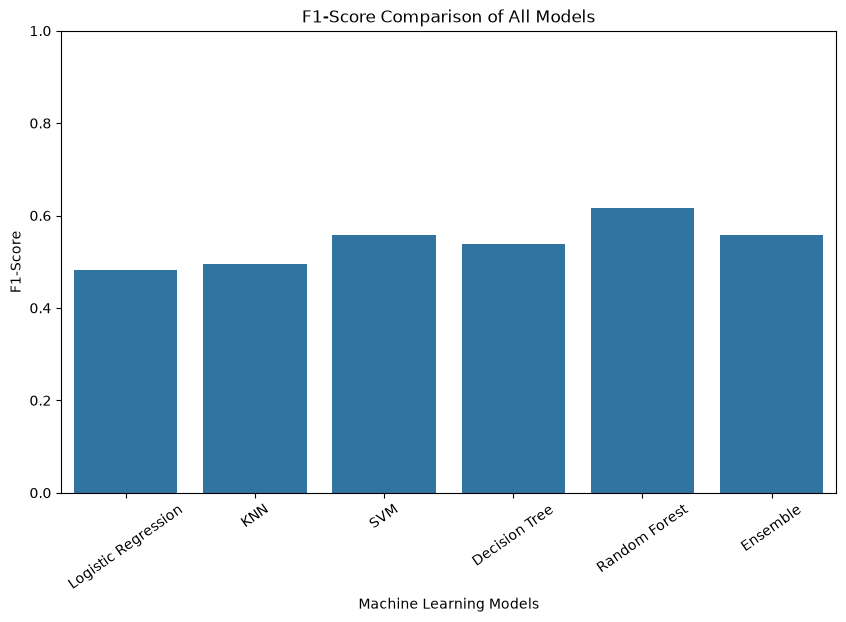

In [137]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=results_df,
    x='Model',
    y='F1-Score')

plt.title('F1-Score Comparison of All Models')
plt.xlabel('Machine Learning Models')
plt.ylabel('F1-Score')
plt.xticks(rotation=35)
plt.ylim(0, 1)
plt.show()

### Cell 62 overview
Compare model F1 scores in a bar chart. F1 provides a single balance of precision and recall; also inspect the positive-class report to understand the trade-off behind each score.


In [138]:
pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),  
    ('classifier', RandomForestClassifier(random_state=42))])

### Chart analysis
Use this plot to identify which classifier has the best F1 score on the held-out test set and how large the gaps are. A higher F1 indicates a better balance between precision and recall for the scored positive class, but it does not reveal which error type dominates. Confirm the result with each model’s classification report and make sure the predictions were produced from the same test rows.

# 8. Final Tuning and Confusion Matrix


### Cell 63 overview
Create a final pipeline that applies preprocessing and then fits a Random Forest. A single pipeline keeps transformations aligned between cross-validation and prediction.


In [139]:
grid_search = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,   
    cv=5)

grid_search.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'classifier__max_depth': [10, 20, ...], 'classifier__min_samples_split': [2, 5], 'classifier__n_estimators': [50, 100, ...]}"
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",None
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"ve

### Cell 64 overview
Tune the final pipeline with cross-validation on the training set. Specify the scoring metric explicitly so selection matches the evaluation goal.


Classification Report:
              precision    recall  f1-score   support

       False       0.92      0.97      0.94      2084
        True       0.75      0.51      0.61       382

    accuracy                           0.90      2466
   macro avg       0.83      0.74      0.77      2466
weighted avg       0.89      0.90      0.89      2466



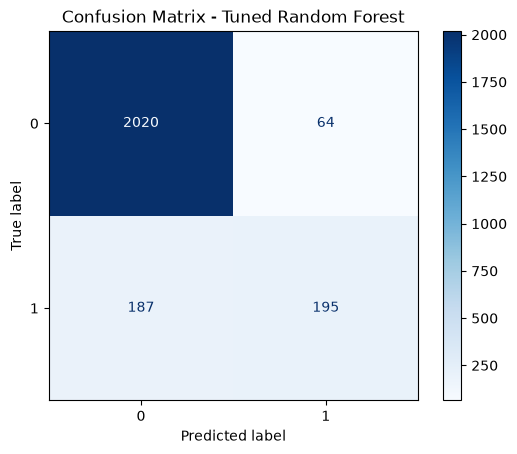

In [140]:
y_pred = grid_search.predict(X_test)

print("Classification Report:")
print(classification_report(y_test, y_pred))

cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot(cmap=plt.cm.Blues)
plt.title("Confusion Matrix - Tuned Random Forest")
plt.show()

# 9. Site Section


In [141]:
best_model_pipeline = grid_search.best_estimator_

model_filename = "shopping_intention_model.joblib"
joblib.dump(best_model_pipeline, model_filename)

print(f"Model successfully saved to file{model_filename}Saved .")

loaded_model = joblib.load(model_filename)
sample_pred = loaded_model.predict(X_test.iloc[:1])
sample_prob = loaded_model.predict_proba(X_test.iloc[:1])
print(f"Model Load Test - Prediction Result: {sample_pred[0]} (Likelihood of purchase: {sample_prob[0][1]:.2%})")

Model successfully saved to fileshopping_intention_model.joblibSaved .
Model Load Test - Prediction Result: False (Likelihood of purchase: 1.91%)


In [142]:
MODEL_PATH = "shopping_intention_model.joblib"

try:
    _model = joblib.load(MODEL_PATH)
    print("The model was loaded successfully.")
except Exception as e:
    _model = None
    print(f"Error loading model: {e}")

def predict_intention(data: Dict[str, Any]) -> Tuple[bool, float]:
    """
   Retrieving user session data as a dictionary, and returning a prediction and the probability of purchase.
    """
    if _model is None:raise RuntimeError("The model has not been loaded. Check the joblib file.")
    
    
    df_input = pd.DataFrame([data])
    
    numeric_cols = [
        'Administrative', 'Administrative_Duration', 'Informational',
        'Informational_Duration', 'ProductRelated', 'ProductRelated_Duration',
        'BounceRates', 'ExitRates', 'PageValues', 'SpecialDay',
        'OperatingSystems', 'Browser', 'Region', 'TrafficType']

    for col in numeric_cols:
        if col in df_input.columns:
            df_input[col] = pd.to_numeric(df_input[col])
            
    if 'Weekend' in df_input.columns:
        df_input['Weekend'] = df_input['Weekend'].astype(bool)

    prediction = bool(_model.predict(df_input)[0])
    probability = float(_model.predict_proba(df_input)[0][1])
    
    return prediction, probability

dummy_input = {
    'Administrative': 0,
    'Administrative_Duration': 0.0,
    'Informational': 0,
    'Informational_Duration': 0.0,
    'ProductRelated': 10,
    'ProductRelated_Duration': 627.5,
    'BounceRates': 0.02,
    'ExitRates': 0.05,
    'PageValues': 15.0,
    'SpecialDay': 0.0,
    'Month': 'Nov',
    'OperatingSystems': 2,
    'Browser': 2,
    'Region': 1,
    'TrafficType': 2,
    'VisitorType': 'Returning_Visitor',
    'Weekend': False}

pred, prob = predict_intention(dummy_input)
print(f"Purchase result: {pred} | Likelihood of purchase: {prob:.2%}")

The model was loaded successfully.
Purchase result: False | Likelihood of purchase: 49.78%


In [143]:
MODEL_PATH = "shopping_intention_model.joblib"

try:
    _model = joblib.load(MODEL_PATH)
except Exception as e:
    _model = None

def predict_intention(data: Dict[str, Any]) -> Tuple[bool, float]:
    if _model is None:
        raise RuntimeError("The model has not been loaded.")
    
    df_input = pd.DataFrame([data])
    
    numeric_cols = [
        'Administrative', 'Administrative_Duration', 'Informational',
        'Informational_Duration', 'ProductRelated', 'ProductRelated_Duration',
        'BounceRates', 'ExitRates', 'PageValues', 'SpecialDay',
        'OperatingSystems', 'Browser', 'Region', 'TrafficType']
    
    for col in numeric_cols:
        if col in df_input.columns:
            df_input[col] = pd.to_numeric(df_input[col])
            
    if 'Weekend' in df_input.columns:
        df_input['Weekend'] = df_input['Weekend'].astype(bool)

    prediction = bool(_model.predict(df_input)[0])
    probability = float(_model.predict_proba(df_input)[0][1])
    
    return prediction, probability